# Gaussian toy: sync vs no sync

Train two vector fields on the **same Gaussian source and two terminal Gaussian populations** and compare the learned routes. The primary space is 2D; a known map adds a Gaussian bump in the 3D secondary space. Only the start and end distributions are observed. The model receives **no intermediate detour trajectory**.

**Without sync:** the primary-only objective favors a short route. **With sync:** the mapped route also contributes energy and endpoint matching. Both use identical initial network weights, data, architecture and training budget. The known map isolates synchronization from map-estimation error. This is a controlled synthetic demonstration, not a biological benchmark.

Install `.[notebooks,visualization]`. The primary is already 2D, so vector-field arrows are drawn directly in training coordinates. For biological AnnData/UMAP flow, see [the gastrulation tutorial](07_dynamics.ipynb).

In [1]:
from pathlib import Path
import uuid
import numpy as np
import torch
import matplotlib.pyplot as plt
import coati as ct
from coati.toy_comparison import (
    make_shared_initial_checkpoint, plot_gaussian_sync,
    plot_bump_height, compare_gaussian_runs,
)
%matplotlib inline

## Paired Gaussian endpoints and a known map

The initial center is $(0.30,0.30)$; the two terminal centers are $(0.5,0.8)$ and $(0.8,0.5)$. The bump lies between them at $(0.5,0.5)$, with height 1 and width 0.08. These centers and map geometry follow the paper toy example. Compact, distinct covariance matrices follow the original toy data generator; observations are sampled inside $[0,1]^2$. The total cell count stays at 128 at both times, with 64 observed cells in each terminal component. Each secondary observation is the exact mapped image of its paired primary observation. The map is fixed throughout fitting:

$$T(x_1,x_2)=(x_1,x_2,h(x)),\qquad h(x)=H\exp\!\left(-\frac{\|x-c\|^2}{2s^2}\right).$$

The secondary clouds are pushforwards of primary Gaussians, rather than Gaussians in 3D. The bump encodes the extra geometric information.

The sampling covariances are $\Sigma_0=\left(\begin{smallmatrix}0.0042&0.0002\\0.0002&0.0038\end{smallmatrix}\right)$, $\Sigma_1=\left(\begin{smallmatrix}0.0030&0.0001\\0.0001&0.0030\end{smallmatrix}\right)$ and $\Sigma_2=\left(\begin{smallmatrix}0.0032&-0.0001\\-0.0001&0.0032\end{smallmatrix}\right)$. These finite compact clouds are a tutorial sampling choice, rather than the identity covariance written in the manuscript.

In [2]:
SEED = 7
N_CELLS = 128
ITERATIONS = 3000
SECONDARY_WEIGHT = .7
HEIGHT, WIDTH, CENTER = 1., .08, (.5, .5)
data = ct.datasets.gaussian_sync(n=N_CELLS, seed=SEED, height=HEIGHT, width=WIDTH, center=CENTER)
T = ct.datasets.gaussian_bump_map(height=HEIGHT, width=WIDTH, center=CENTER)
print("Observed times:", data.times)
print("Primary / secondary:", data.primary[0].shape, data.secondary[0].shape)

Observed times: [0. 1.]
Primary / secondary: (128, 2) (128, 3)


## Switch synchronization, keep the other settings fixed

`multimodal=False` disables secondary training. `multimodal=True` enables the mapped secondary energy and marginal matching; `secondary_weight` controls the energy mixture. Setting that weight to zero alone is not the no-sync baseline, because secondary marginal matching would remain enabled.

No manifold penalty is used here. Coordinates remain in raw toy units in both fits; the costs below are not W2-normalized to one.

In [3]:
base = ct.Config(
    multimodal=False, balanced=True, iterations=ITERATIONS,
    batch_size=64, learning_rate=.003, hidden_dim=64, n_layers=3,
    activation="tanh", matching_weight=300., energy_weight=1.,
    manifold_weight=0., dt=.05, seed=SEED,
)
configs = {
    "Without sync": base,
    "With sync": base.with_parameters(multimodal=True, secondary_weight=SECONDARY_WEIGHT),
}

## Train both vector fields from identical weights

A common weight-only checkpoint guarantees identical initialization while leaving both optimizers fresh. The seed is shared; stochastic minibatch draws are not asserted to be identical. Each model writes its normal training checkpoint/logs to a fresh directory.

In [4]:
run_dir = Path("outputs") / ("gaussian-sync-" + uuid.uuid4().hex[:8])
initial_checkpoint = make_shared_initial_checkpoint(base, run_dir / "initial.pt")
results = {}
for name, config in configs.items():
    results[name] = ct.train_vector_field(
        data, config, output_dir=run_dir / ("with_sync" if config.multimodal else "without_sync"),
        T_model=T if config.multimodal else None,
        warm_start_path=initial_checkpoint,
    )
    print(name, "trained for", ITERATIONS, "iterations")

Without sync trained for 3000 iterations


With sync trained for 3000 iterations


## Integrate the learned fields and apply the same map

Both fits start from all the same observed initial cells. Apply the known map to both predictions for comparison, including the baseline whose fitting did not use secondary information. No secondary velocity field is independently learned.

In [5]:
predictions = {}
for name, result in results.items():
    prediction = result.predict_trajectory(times=np.linspace(0., 1., 41))
    with torch.no_grad():
        prediction["secondary"] = T(torch.tensor(prediction["primary"])).numpy()
    assert np.isfinite(prediction["primary"]).all()
    np.testing.assert_array_equal(prediction["secondary"][..., :2], prediction["primary"])
    predictions[name] = prediction

## Compare trajectories and the learned vector fields

Top: the actual primary coordinates, three density contours per observed Gaussian, and learned vector-field arrows at $t=0.5$. The orange background indicates the mapped bump height. Bottom: those same trajectories mapped onto the secondary surface. Axes, viewpoints, surface geometry and the 18 displayed initial-cell indices are identical across fits; the two thick lines are endpoint-group means, assigned to the nearest observed terminal Gaussian center for visualization. They avoid averaging the two destinations into an unobserved midpoint. These groups do not force either fitted route.

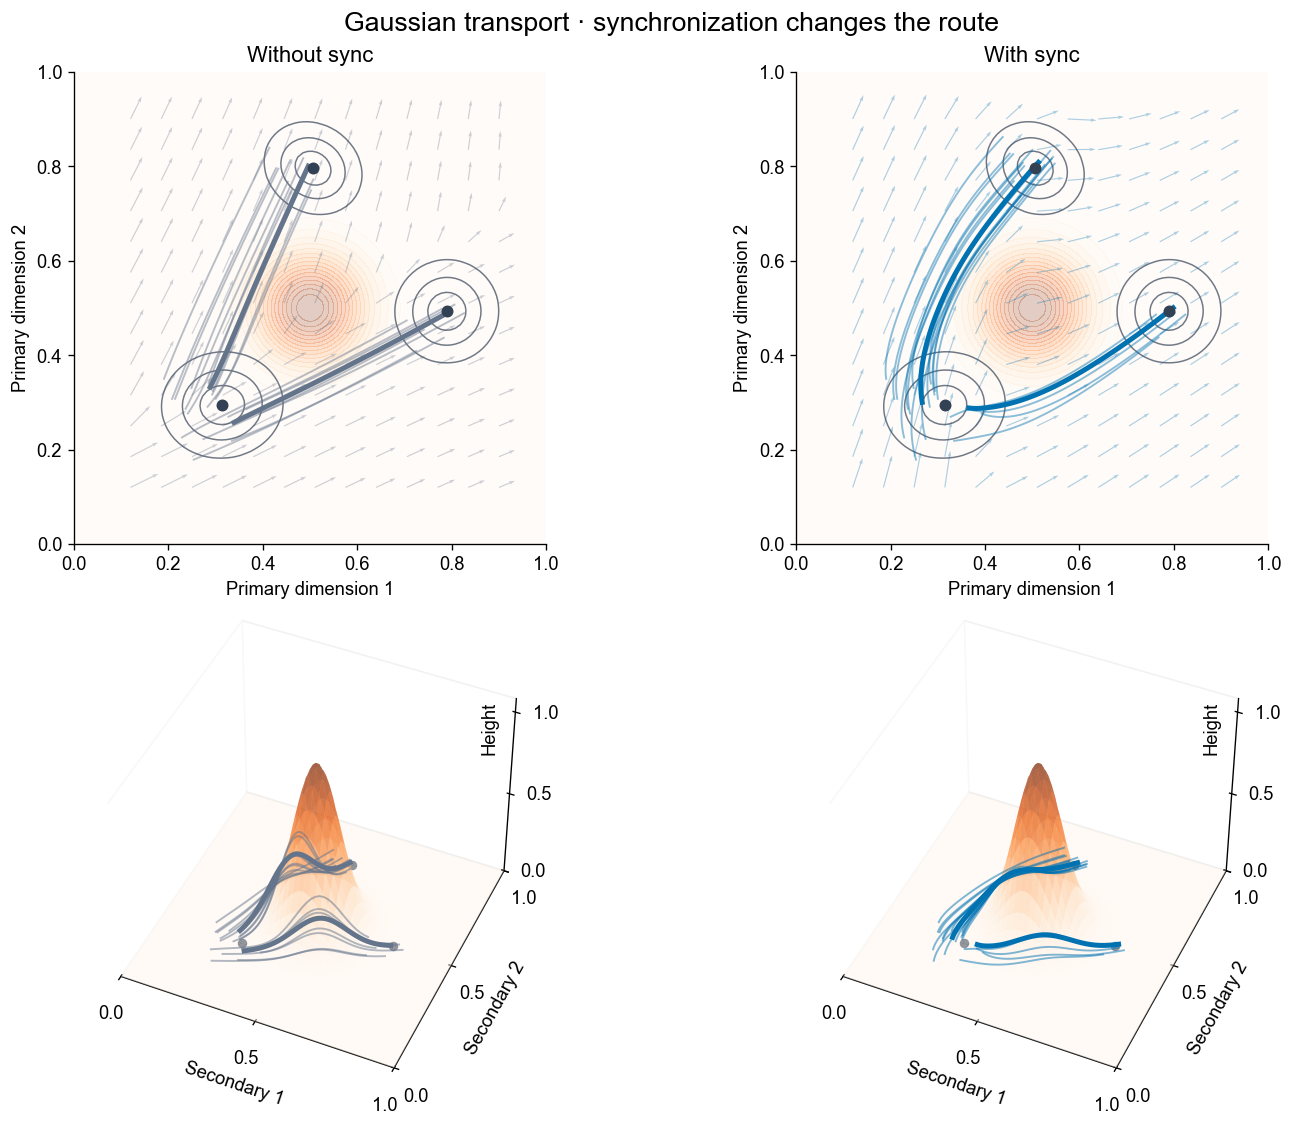

In [6]:
plot_gaussian_sync(data, T, results, predictions)
plt.show()

## Does the learned route climb the bump?

Plot mapped height along all 128 trajectories. The shaded range is the across-path interquartile range, not a confidence interval.

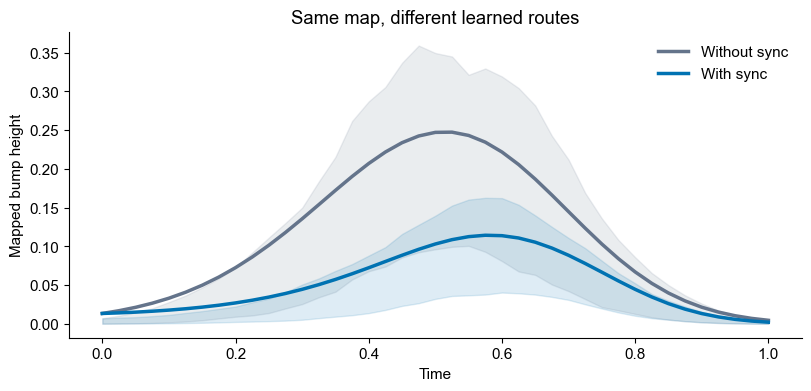

In [7]:
plot_bump_height(predictions)
plt.show()

## Compare mapped cost and endpoint fit

Secondary kinetic energy is evaluated on the same 41-point grid with the same map for both fits. It is the average of $\frac12\sum_k\|T(x_{k+1})-T(x_k)\|^2/\Delta t_k$. Inspect primary endpoint Sinkhorn alongside the two kinetic costs: synchronization can lower mapped cost while increasing primary path cost and changing endpoint fit.

In [8]:
scores = compare_gaussian_runs(results, predictions)
print("Primary observed sampling floor:", results["Without sync"].metadata["floor_primary"][-1])
scores.round(5)

Primary observed sampling floor: 0.0010295554529875517


,Primary endpoint Sinkhorn,Primary kinetic energy,Secondary kinetic energy,Median maximum bump height
Model,,,,
Without sync,0.00026,0.12891,0.51701,0.21688
With sync,0.00044,0.15397,0.26210,0.09118


The two synchronized branches pass around opposite sides of the bump, while the primary-only paths are closer to straight transport. Both are generated by trained COATI vector fields, without intermediate path supervision. Endpoint constraints are soft: inspect endpoint matching alongside the route. This single-seed geometric illustration does not establish a general accuracy advantage or an exact global optimum. Change `SECONDARY_WEIGHT`, bump geometry or seed to explore the tradeoff.